# ЛР6 — хранение, очистка и качество данных
**Вариант 4: погода и наблюдения.** Источники:
* HTML — справочник городов России с координатами (time-in.ru);
* API — архив суточной погоды Open-Meteo.

Пайплайн: `src/collect.py` → `run_all.py` (порча → пересборка clean → форматы → БД → качество → mart).
Ноутбук только читает результаты, поэтому его можно перезапускать сколько угодно.

In [1]:
import json, sqlite3, sys, tempfile, shutil
from collections import Counter
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from common import RAW_FILES, read_jsonl, CLEAN, MART, DB_PATH
import contract, quality
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

need = [RAW_FILES["time-in.ru"][0], RAW_FILES["open-meteo"][0], CLEAN / "dataset.parquet", DB_PATH]
missing = [str(p.relative_to(ROOT)) for p in need if not p.exists()]
if missing:
    raise FileNotFoundError("Нет результатов пайплайна: " + ", ".join(missing) +
                            ". Сначала в корне проекта: python src/collect.py, затем python run_all.py")

## 1. Сырой слой: источники и происхождение

In [2]:
rows = []
for src, files in RAW_FILES.items():
    for f in files:
        recs = read_jsonl([f])
        rows.append({"источник": src, "файл": f.name, "строк": len(recs),
                     "синтетических": sum(1 for r in recs if r.get("_synthetic_corruption")),
                     "run_id": ", ".join(sorted({r.get("_run_id", "") for r in recs})) or "—"})
display(pd.DataFrame(rows))
print("Пример записи HTML:"); print(json.dumps(read_jsonl([RAW_FILES["time-in.ru"][0]])[0], ensure_ascii=False, indent=1))
print("Пример записи API:"); print(json.dumps(read_jsonl([RAW_FILES["open-meteo"][0]])[0], ensure_ascii=False, indent=1))

,источник,файл,строк,синтетических,run_id
0,time-in.ru,locations_html.jsonl,1715,0,"20261102T141656Z_042e96, 20261102T143058Z_5114fe, 20261102T143541Z_199ef0, 20261102T14..."
1,time-in.ru,locations_html_synthetic.jsonl,120,120,"20261102T141656Z_042e96, 20261102T143058Z_5114fe, 20261102T143541Z_199ef0, 20261102T14..."
2,open-meteo,weather_api.jsonl,750,0,20261102T145522Z_fe551f
3,open-meteo,weather_api_synthetic.jsonl,53,53,20261102T145522Z_fe551f


Пример записи HTML:
{
 "_source": "time-in.ru",
 "_source_url": "https://time-in.ru/coordinates/russia",
 "_collected_at": "2026-11-02T14:16:58+00:00",
 "_parser_version": "1.1",
 "_status": 200,
 "_run_id": "20261102T141656Z_042e96",
 "city_raw": "Москва",
 "city_href_raw": "https://time-in.ru/coordinates/moscow",
 "coords_raw": "55.75, 37.62",
 "latitude_raw": "55.75",
 "longitude_raw": "37.62"
}
Пример записи API:
{
 "_source": "nasa-power",
 "_source_url": "https://power.larc.nasa.gov/api/temporal/daily/point?parameters=T2M_MAX%2CT2M_MIN%2CPRECTOTCORR&community=AG&latitude=55.75&longitude=37.62&start=20260927&end=20261026&format=JSON",
 "_endpoint": "power_daily_point",
 "_collected_at": "2026-11-02T14:55:57+00:00",
 "_parser_version": "1.1",
 "_status": 200,
 "_run_id": "20261102T145522Z_fe551f",
 "city_raw": "Москва",
 "latitude_raw": "55.75",
 "longitude_raw": "37.62",
 "date_raw": "2026-09-27",
 "temperature_2m_max_raw": 17.33,
 "temperature_2m_min_raw": 7.67,
 "precipitation_s

In [3]:
check = json.loads((CLEAN / "rebuild_check.json").read_text(encoding="utf-8"))
pd.DataFrame([{"пересборка": k, **{x: check[k][x] for x in ("rebuilt_at", "clean_rows", "rejects", "fingerprint_observations", "fingerprint_locations", "seconds")}}
              for k in ("first", "second")]).assign(одинаково=check["identical"])

,пересборка,rebuilt_at,clean_rows,rejects,fingerprint_observations,fingerprint_locations,seconds,одинаково
0,first,2026-11-02T15:33:45+00:00,"{'locations': 340, 'observations': 750}",1548,da8e77598237a3e2,75a5e4fa4b557aa1,0.23,True
1,second,2026-11-02T15:33:45+00:00,"{'locations': 340, 'observations': 750}",1548,da8e77598237a3e2,75a5e4fa4b557aa1,0.17,True


## 2. Сравнение форматов

In [4]:
pd.read_csv(CLEAN / "format_benchmark.csv")

,format,rows,size_kb,read_full_ms,read_3_cols_ms,observation_time_utc_dtype,day_code_dtype,day_code_example,date_example,precipitation_sum_dtype
0,CSV,750,237.9,3.46,2.91,object,int64,np.int64(927),2026-09-27 00:00:00+00:00,float64
1,JSON Lines,750,409.1,7.00,7.33,object,int64,np.int64(927),2026-09-27T00:00:00.000Z,float64
2,Parquet,750,25.9,1.71,1.26,"datetime64[ns, UTC]",object,'0927',2026-09-27 00:00:00+00:00,Float64


## 3. Протокол очистки (шаги 1–6 + контракт)

In [5]:
protocol = pd.read_csv(CLEAN / "protocol.csv")
protocol

,source,step,rows_before,rows_after,changed,removed,note
0,time-in.ru,1. Нормализация текста,1835,1835,40,0,"NFKC, \xa0, zero-width, пробелы"
1,time-in.ru,2. Бизнес-ключ,1835,1835,1815,0,location_id = транслит-slug названия города (ASCII)
2,time-in.ru,3. Типизация,1835,1835,20,0,"координаты → float (запятая → точка), время сбора → datetime UTC"
3,time-in.ru,4. Пропуски,1835,1795,0,40,"city, latitude, longitude обязательны; ничего не заполняем"
4,time-in.ru,5. Дубликаты,1795,360,0,1435,"полных 1412, по ключу 23 (почти-дубли — 19)"
5,time-in.ru,6. Бизнес-правила,360,340,0,20,"5 правил: широта, долгота, (0,0), длина и алфавит названия"
6,open-meteo,1. Нормализация текста,803,803,5,0,"NFKC, \xa0, zero-width, пробелы"
7,open-meteo,2. Бизнес-ключ,803,803,5,0,observation_id = location_id + дата; из URL убраны utm-метки
8,open-meteo,3. Типизация,803,794,5,9,"числа из текста (запятая → точка), даты → datetime UTC, статус → Int64, day_code — строка"
9,open-meteo,4. Пропуски,794,789,0,5,"обязательные → отбраковка; precipitation_sum необязательное → остаётся NULL, среднее н..."


In [6]:
rej = pd.DataFrame(read_jsonl([CLEAN / "rejects.jsonl"]))
rej["тип"] = rej["synthetic"].map(lambda s: "синтетическая порча" if isinstance(s, str) else "реальные данные")
display(rej.groupby(["source", "step", "тип"]).size().rename("отбраковано").reset_index())
display(rej.groupby(["source", "synthetic"]).agg(записей=("step", "size"), шаг=("step", lambda s: ", ".join(sorted(set(s))))).reset_index())
display(rej[rej["тип"] == "реальные данные"].groupby(["source", "step", "reason"]).size().rename("записей").reset_index())

,source,step,тип,отбраковано
0,open-meteo,3. Типизация,синтетическая порча,9
1,open-meteo,4. Пропуски,синтетическая порча,5
2,open-meteo,5. Дубликаты,синтетическая порча,19
3,open-meteo,6. Бизнес-правила,синтетическая порча,20
4,time-in.ru,4. Пропуски,синтетическая порча,40
5,time-in.ru,5. Дубликаты,реальные данные,1375
6,time-in.ru,5. Дубликаты,синтетическая порча,60
7,time-in.ru,6. Бизнес-правила,синтетическая порча,20


,source,synthetic,записей,шаг
0,open-meteo,comma_decimal,5,5. Дубликаты
1,open-meteo,future_date,4,6. Бизнес-правила
2,open-meteo,invalid_date,4,3. Типизация
3,open-meteo,missing_tmax,5,4. Пропуски
4,open-meteo,nbsp_zero_width_city,5,5. Дубликаты
5,open-meteo,near_duplicate_older,4,5. Дубликаты
6,open-meteo,negative_precip,4,6. Бизнес-правила
7,open-meteo,non_numeric_tmax,5,3. Типизация
8,open-meteo,temp_out_of_range,4,6. Бизнес-правила
9,open-meteo,tmax_lt_tmin,4,6. Бизнес-правила


,source,step,reason,записей
0,time-in.ru,5. Дубликаты,дубль по ключу: оставлена самая свежая запись,3
1,time-in.ru,5. Дубликаты,полный дубль (те же ключ и значения),1372


## 4. Контракт данных: заведомо битые записи

In [7]:
pd.DataFrame(contract.demo_broken())

,проверка,результат,поле,сообщение
0,эталонная запись,принята,,
1,широта вне диапазона (Field le=90),отбракована,latitude,Input should be less than or equal to 90
2,наивная дата без таймзоны (field_validator utc_only),отбракована,observation_time_utc,"Value error, наивная дата без таймзоны; ожидается UTC"
3,кириллический ключ (field_validator slug_format),отбракована,location_id,"Value error, location_id должен быть ASCII-slug"
4,utm-метки в URL (field_validator no_tracking),отбракована,source_url,"Value error, URL содержит метки трекинга utm_*"
5,осадки < 0 (Field ge=0),отбракована,precipitation_sum,Input should be greater than or equal to 0
6,пустой город (min_length=2),отбракована,city,String should have at least 2 characters
7,day_code без ведущего нуля (pattern),отбракована,day_code,String should match pattern '^(0[1-9]|1[0-2])(0[1-9]|[12]\d|3[01])$'
8,tmax < tmin (model_validator),отбракована,model,"Value error, temperature_2m_max < temperature_2m_min"
9,ключ не совпадает с датой (model_validator),отбракована,model,"Value error, observation_id ≠ location_id + '_' + дата (moskva_2026-09-30)"


## 5. База данных: идемпотентность, история (SCD2), ограничения

In [8]:
demo = json.loads((ROOT / "db" / "idempotency_demo.json").read_text(encoding="utf-8"))
display(pd.DataFrame(demo["runs"]).drop(columns=["run_at"]))
print("Прогон 2 — строк с неизменным updated_at:", demo["run2_rows_with_same_updated_at"])
print("Изменённые в прогоне 3 ключи:", demo["changed_keys"])
display(pd.DataFrame(demo["history_of_changed"]))
s = demo["scd2_state_as_of_run2"]
print(f"Состояние на момент прогона 2 ({s['as_of']}): {s['then']}\nСостояние сейчас: {s['now']}")

,label,rows_in,inserted,updated,unchanged,rows_total,history_versions
0,1. исходный,750,750,0,0,750,750
1,"2. повторный, те же данные",750,0,0,750,750,750
2,3. изменены две записи,750,0,2,748,750,752


Прогон 2 — строк с неизменным updated_at: 750
Изменённые в прогоне 3 ключи: ['abakan_2026-09-27', 'armavir_2026-10-12']


,observation_id,valid_from,valid_to,is_current,temperature_2m_max,temperature_2m_min,precipitation_sum,collected_at
0,abakan_2026-09-27,2026-11-02T15:33:45.746444+00:00,2026-11-02T15:33:45.778388+00:00,0,9.64,2.55,2.65,2026-11-02T14:55:59+00:00
1,abakan_2026-09-27,2026-11-02T15:33:45.778388+00:00,None,1,11.10,2.55,2.65,2026-11-02T14:55:59+00:00
2,armavir_2026-10-12,2026-11-02T15:33:45.746444+00:00,2026-11-02T15:33:45.778388+00:00,0,25.80,12.02,0.00,2026-11-02T14:56:21+00:00
3,armavir_2026-10-12,2026-11-02T15:33:45.778388+00:00,None,1,25.80,12.02,2.40,2026-11-02T14:56:21+00:00


Состояние на момент прогона 2 (2026-11-02T15:33:45.769492+00:00): ['abakan_2026-09-27', 9.64, 2.65]
Состояние сейчас: ['abakan_2026-09-27', 11.1, 2.65]


In [9]:
pd.DataFrame(demo["constraint_checks"])

,проверка,результат,сообщение БД
0,дубликат первичного ключа (обычный INSERT),отвергнуто,UNIQUE constraint failed: observations.observation_id
1,CHECK: tmax < tmin,отвергнуто,CHECK constraint failed: temperature_2m_max >= temperature_2m_min
2,CHECK: осадки < 0,отвергнуто,CHECK constraint failed: precipitation_sum IS NULL OR precipitation_sum BETWEEN 0 AND 500
3,CHECK: дата без таймзоны,отвергнуто,CHECK constraint failed: observation_time_utc LIKE '%+00:00'
4,NOT NULL: нет температуры,отвергнуто,NOT NULL constraint failed: observations.temperature_2m_max
5,FOREIGN KEY: неизвестная локация,отвергнуто,FOREIGN KEY constraint failed
6,UNIQUE: второй замер того же города за те же сутки,отвергнуто,"UNIQUE constraint failed: observations.location_id, observations.observation_time_utc"


In [10]:
with sqlite3.connect(DB_PATH) as conn:
    display(pd.read_sql("SELECT label, rows_in, inserted, updated, unchanged, rows_total, history_versions FROM load_runs", conn))
    display(pd.read_sql("SELECT (SELECT COUNT(*) FROM locations) AS locations, (SELECT COUNT(*) FROM observations) AS observations, "
                        "(SELECT COUNT(*) FROM observations_history) AS history, (SELECT COUNT(*) FROM rejects) AS rejects", conn))

,label,rows_in,inserted,updated,unchanged,rows_total,history_versions
0,load,750,750,0,0,750,750
1,load,750,0,0,750,750,750


,locations,observations,history,rejects
0,340,750,750,1548


## 6. Метрики качества и светофор

In [11]:
metrics = pd.read_csv(CLEAN / "quality_metrics.csv")
verdict = json.loads((CLEAN / "quality_verdict.json").read_text(encoding="utf-8"))
display(metrics)
print("Итоговый вердикт:", verdict["verdict"].upper())

,metric,value,green,yellow,status,note
0,completeness_required,100.00,≥ 99.0,≥ 95.0,green,8 обязательных полей
1,completeness_optional,100.00,≥ 95.0,≥ 80.0,green,precipitation_sum (NULL не заполняется)
2,key_uniqueness,100.00,≥ 100.0,≥ 99.5,green,observation_id
3,validity,93.40,≥ 95.0,≥ 85.0,yellow,"750 чистых из 803 сырых (реальных 750, синтетических 53)"
4,reject_rate,6.60,≤ 5.0,≤ 15.0,yellow,6. Бизнес-правила: 20; 5. Дубликаты: 19; 3. Типизация: 9; 4. Пропуски: 5
5,business_rules_violations,2.60,≤ 1.0,≤ 5.0,yellow,20 из 770 записей на шаге 6
6,cross_source_consistency,100.00,≥ 100.0,≥ 98.0,green,"доля наблюдений, чья локация есть в справочнике HTML"
7,freshness_days,7.65,≤ 8.0,≤ 11.0,green,последнее наблюдение 2026-10-26; источник nasa-power публикует данные с задержкой ~7 с...
8,coverage_city_days,100.00,≥ 98.0,≥ 90.0,green,750 из 750 пар «город × сутки»
9,volume_change_pct,0.00,≤ 10.0,≤ 20.0,green,"было 750, стало 750"


Итоговый вердикт: YELLOW


Проверка шлюза: на копии чистого слоя удаляем 40 % наблюдений (имитация поломки источника) — светофор должен стать красным, а загрузка в mart прерваться.

In [12]:
tmp = Path(tempfile.mkdtemp())
for f in CLEAN.glob("*"):
    if f.is_file():
        shutil.copy(f, tmp / f.name)
broken = pd.read_parquet(tmp / "dataset.parquet").sample(frac=0.6, random_state=1)
broken.to_parquet(tmp / "dataset.parquet", index=False)
m2, meta2 = quality.compute(clean_dir=tmp)
display(m2[m2.status != "green"][["metric", "value", "status", "note"]])
try:
    quality.check_gate(meta2)
except quality.QualityGateError as e:
    print("QualityGateError:", e)
shutil.rmtree(tmp)

,metric,value,status,note
3,validity,56.04,red,"450 чистых из 803 сырых (реальных 750, синтетических 53)"
4,reject_rate,6.60,yellow,6. Бизнес-правила: 20; 5. Дубликаты: 19; 3. Типизация: 9; 4. Пропуски: 5
5,business_rules_violations,2.60,yellow,20 из 770 записей на шаге 6
8,coverage_city_days,60.00,red,450 из 750 пар «город × сутки»
9,volume_change_pct,40.00,red,"было 750, стало 450"


QualityGateError: Светофор КРАСНЫЙ: validity, coverage_city_days, volume_change_pct. Загрузка в mart прервана.


## 7. Слой mart

In [13]:
for name in ("city_stats", "daily_dynamics", "top_warmest"):
    v = pd.read_parquet(MART / "views" / f"{name}.parquet")
    print(f"mart/views/{name}.parquet — {len(v)} строк"); display(v.head(10))

mart/views/city_stats.parquet — 25 строк


,location_id,city,latitude,days,avg_tmax,avg_tmin,precip_total,rainy_days
0,abakan,Абакан,53.72,30,7.3,-0.4,49.1,26
1,adler,Адлер,43.43,30,19.7,14.9,82.2,23
2,azov,Азов,47.11,30,21.1,12.0,18.3,14
3,aleksandrov,Александров,56.40,30,12.2,4.4,20.1,22
4,aleksin,Алексин,54.51,30,13.8,5.4,8.6,17
5,almetevsk,Альметьевск,54.90,30,13.5,4.0,11.8,10
6,anadyr,Анадырь,64.73,30,1.6,-1.9,53.2,27
7,anapa,Анапа,44.89,30,21.6,13.5,33.7,19
8,angarsk,Ангарск,52.54,30,6.8,-2.0,33.9,26
9,anzhero-sudzhensk,Анжеро-Судженск,56.08,30,5.8,-0.1,54.6,27


mart/views/daily_dynamics.parquet — 30 строк


,day,cities,avg_tmax,avg_tmin,avg_precip
0,2026-09-27,25,16.44,7.79,1.45
1,2026-09-28,25,15.34,6.94,3.48
2,2026-09-29,25,14.98,6.18,2.28
3,2026-09-30,25,15.56,5.62,4.50
4,2026-10-01,25,13.36,5.86,0.59
5,2026-10-02,25,11.93,4.29,1.67
6,2026-10-03,25,12.10,3.75,0.60
7,2026-10-04,25,12.62,3.93,0.79
8,2026-10-05,25,12.93,4.85,1.55
9,2026-10-06,25,13.24,5.95,1.93


mart/views/top_warmest.parquet — 10 строк


,location_id,city,latitude,days,avg_tmax,avg_tmin,precip_total,rainy_days
0,astrakhan,Астрахань,46.35,30,21.8,10.9,1.5,6
1,anapa,Анапа,44.89,30,21.6,13.5,33.7,19
2,armavir,Армавир,44.99,30,21.3,10.9,31.9,16
3,azov,Азов,47.11,30,21.1,12.0,18.3,14
4,adler,Адлер,43.43,30,19.7,14.9,82.2,23
5,balashov,Балашов,51.55,30,17.6,7.4,6.1,11
6,balakovo,Балаково,52.03,30,17.0,6.2,2.3,9
7,artem,Артём,43.36,30,13.9,4.0,134.3,24
8,aleksin,Алексин,54.51,30,13.8,5.4,8.6,17
9,arzamas,Арзамас,55.39,30,13.6,4.9,10.2,13


In [14]:
parts = sorted(p.name for p in (MART / "snapshots").iterdir() if p.is_dir())
print("Партиции:", parts)
one = pd.read_parquet(MART / "snapshots" / parts[-1])
print(f"Прочитана одна партиция {parts[-1]}: {len(one)} строк, {one['location_id'].nunique()} городов")

Партиции: ['dt=2026-11-02']
Прочитана одна партиция dt=2026-11-02: 750 строк, 25 городов


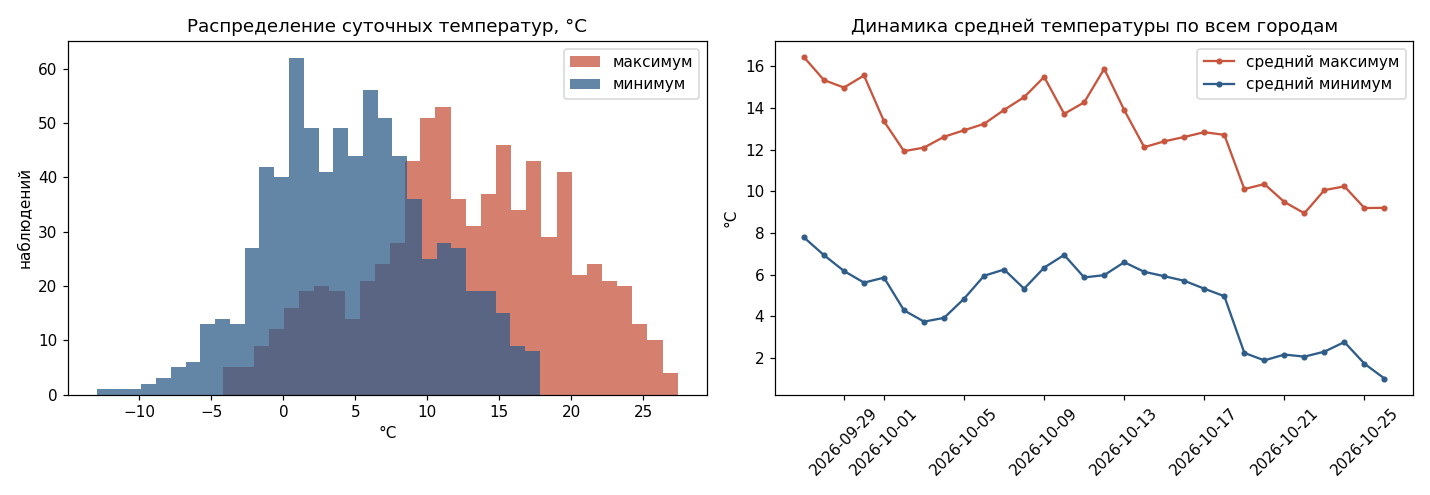

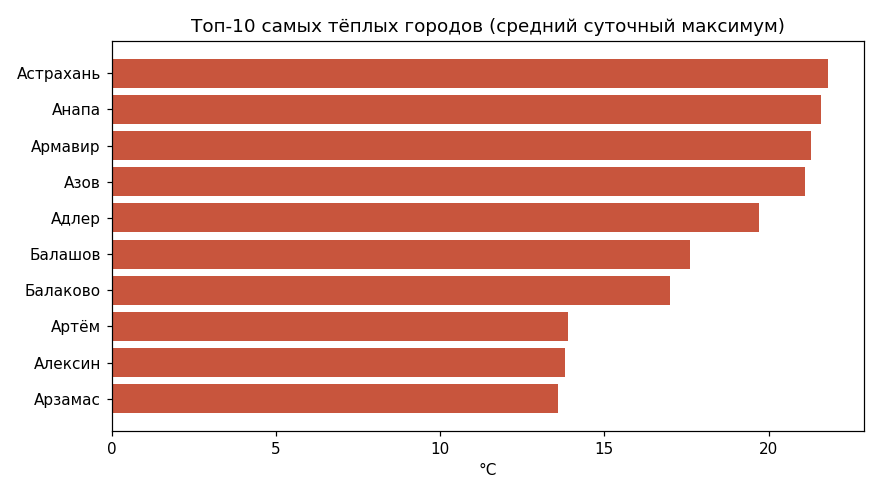

In [15]:
display(Image(filename=str(MART / "temperature_charts.png")))
display(Image(filename=str(MART / "top_warmest.png")))